<a href="https://colab.research.google.com/github/bhaveshpothula/PBL-Machine-Learning-Projects/blob/main/PBL3_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PBL III — Air Quality Classification Using Ensemble Machine Learning

**PBL scope from the presentation:** Logistic Regression, Random Forest, AdaBoost and Gradient Boosting; four-feature vs nine-feature inputs; original vs cleaned data; 16 experiments.

**Evaluation:** one stratified 80/20 split (random seed 42), 3-fold cross-validation using Macro-F1, and held-out test metrics: Accuracy, Precision, Recall, Macro-F1, Weighted-F1 and multiclass One-vs-Rest ROC-AUC.

> Upload the exact PBL-III dataset: `updated_pollution_dataset.csv` (5,000 rows, 9 numeric inputs and the `Air Quality` target). This notebook deliberately checks the schema before running so a different CSV, such as the PBL-II UCI dataset, is not accidentally used.


## 1. Install/import libraries

In [1]:
!pip -q install seaborn scikit-learn

import os, glob, zipfile, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc
)
from sklearn.inspection import permutation_importance
from sklearn.base import clone

warnings.filterwarnings("ignore")
SEED = 42
sns.set_theme(style="whitegrid")
print("Imports ready.")


Imports ready.


## 2. Upload and validate the correct dataset

In [2]:
EXPECTED_FILE = "updated_pollution_dataset.csv"
uploaded = files.upload()

csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
if not csv_files:
    raise FileNotFoundError("No CSV uploaded. Upload updated_pollution_dataset.csv.")

# Prefer the exact project filename; otherwise inspect the only uploaded CSV.
if EXPECTED_FILE in uploaded:
    csv_name = EXPECTED_FILE
elif len(csv_files) == 1:
    csv_name = csv_files[0]
else:
    raise ValueError(f"More than one CSV uploaded: {csv_files}. Upload only {EXPECTED_FILE}.")

df = pd.read_csv(csv_name, encoding="utf-8-sig")
df.columns = df.columns.astype(str).str.strip()
print("Loaded:", csv_name)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Saving updated_pollution_dataset.csv to updated_pollution_dataset.csv
Loaded: updated_pollution_dataset.csv
Shape: (5000, 10)
Columns: ['Temperature', 'Humidity', 'PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'Proximity_to_Industrial_Areas', 'Population_Density', 'Air Quality']


,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality
0,29.8,59.1,5.2,17.9,18.9,9.2,1.72,6.3,319,Moderate
1,28.3,75.6,2.3,12.2,30.8,9.7,1.64,6.0,611,Moderate
2,23.1,74.7,26.7,33.8,24.4,12.6,1.63,5.2,619,Moderate
3,27.1,39.1,6.1,6.3,13.5,5.3,1.15,11.1,551,Good
4,26.5,70.7,6.9,16.0,21.9,5.6,1.01,12.7,303,Good


## 3. Define project features and check schema

In [3]:
target = "Air Quality"
features4 = ["PM2.5", "PM10", "Temperature", "Humidity"]
features9 = [
    "Temperature", "Humidity", "PM2.5", "PM10", "NO2", "SO2", "CO",
    "Proximity_to_Industrial_Areas", "Population_Density"
]
class_order = ["Good", "Moderate", "Poor", "Hazardous"]
required_cols = features9 + [target]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    print("ACTUAL CSV COLUMNS:", df.columns.tolist())
    raise ValueError(
        "This is not the expected PBL-III dataset. Missing columns: "
        + str(missing_cols)
        + ". Upload updated_pollution_dataset.csv, not the PBL-II AirQualityUCI.csv."
    )

data = df[required_cols].copy()
for col in features9:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data[target] = data[target].astype("string").str.strip()

unexpected = sorted(set(data[target].dropna().unique()) - set(class_order))
if unexpected:
    raise ValueError(f"Unexpected Air Quality labels: {unexpected}. Expected {class_order}.")

print("Rows:", len(data))
print("Columns used:", len(required_cols))
print("Missing cells:", int(data.isna().sum().sum()))
print("Duplicate rows:", int(data.duplicated().sum()))
print("\nData types:")
display(data.dtypes.to_frame("dtype"))
print("\nClass counts:")
display(data[target].value_counts().reindex(class_order).rename("Count").to_frame())
print("\nClass percentages:")
display((data[target].value_counts(normalize=True).reindex(class_order)*100).round(1).rename("Share (%)").to_frame())


Rows: 5000
Columns used: 10
Missing cells: 0
Duplicate rows: 0

Data types:


,dtype
Temperature,float64
Humidity,float64
PM2.5,float64
PM10,float64
NO2,float64
SO2,float64
CO,float64
Proximity_to_Industrial_Areas,float64
Population_Density,int64
Air Quality,string[python]



Class counts:


,Count
Air Quality,
Good,2000
Moderate,1500
Poor,1000
Hazardous,500



Class percentages:


,Share (%)
Air Quality,
Good,40.0
Moderate,30.0
Poor,20.0
Hazardous,10.0


## 4. Exploratory Data Analysis (EDA): target distribution

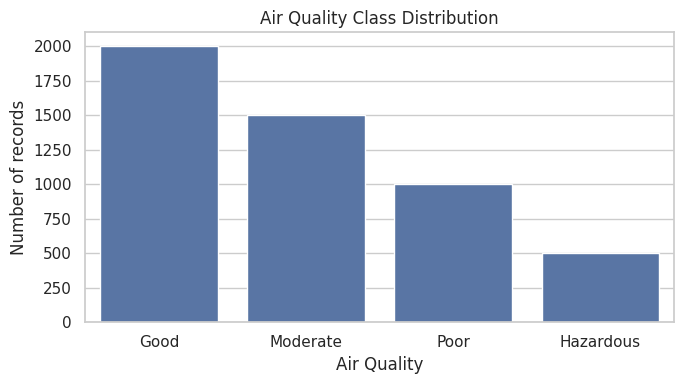

In [4]:
plt.figure(figsize=(7,4))
sns.countplot(data=data, x=target, order=class_order)
plt.title("Air Quality Class Distribution")
plt.xlabel("Air Quality"); plt.ylabel("Number of records")
plt.tight_layout(); plt.show()


## 5. Feature distributions

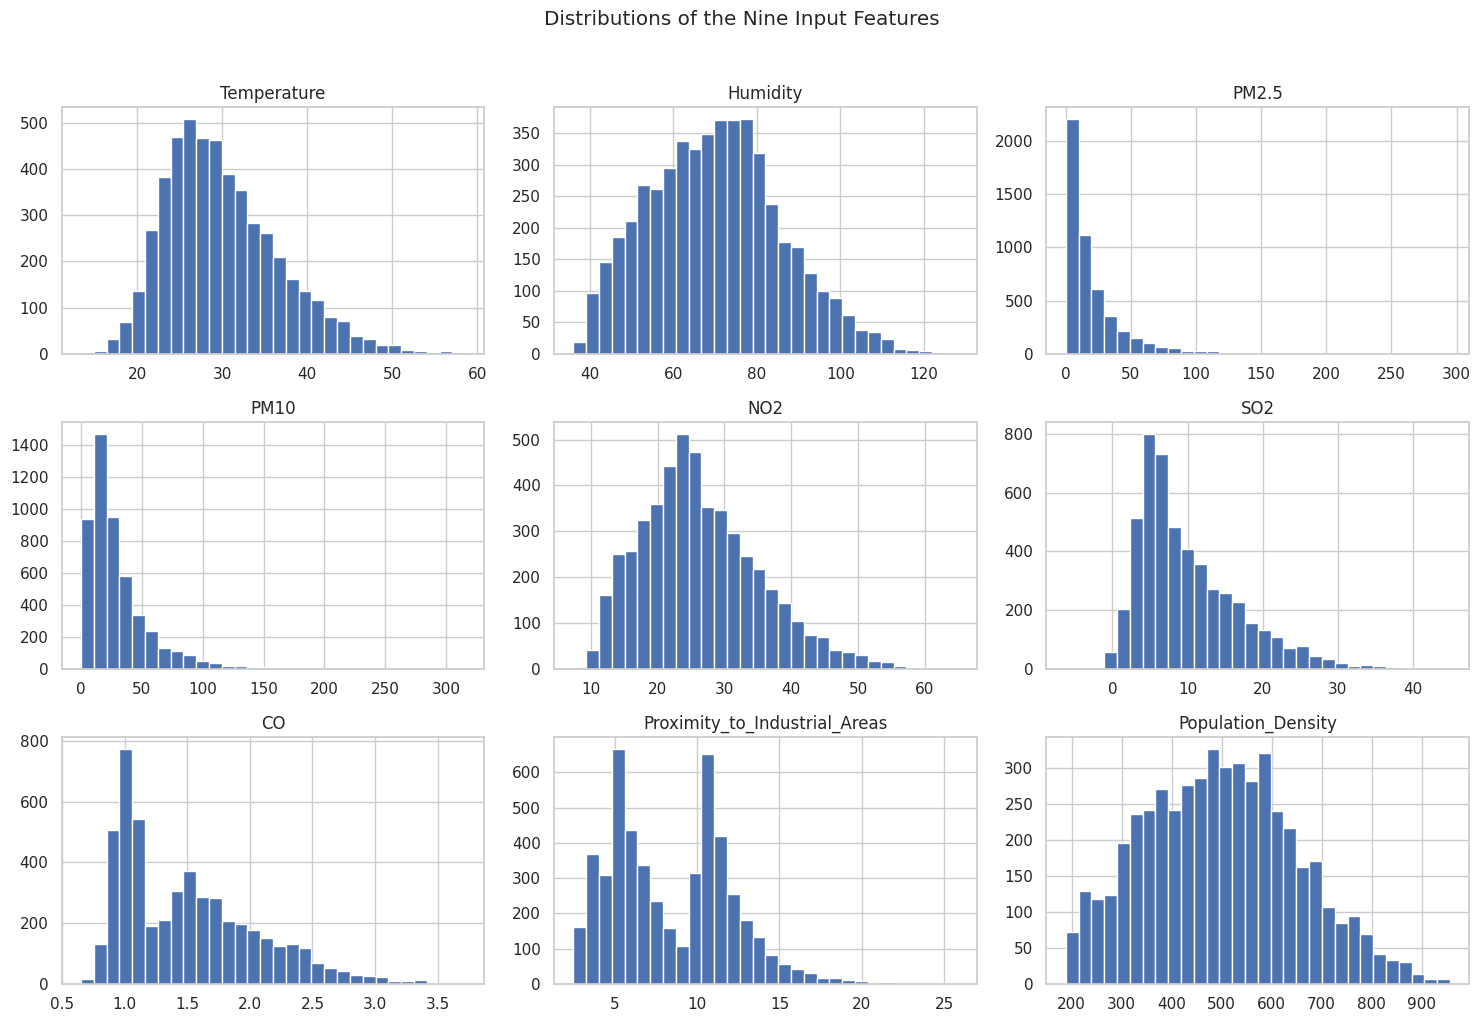

In [5]:
data[features9].hist(figsize=(15,10), bins=30, edgecolor="white")
plt.suptitle("Distributions of the Nine Input Features", y=1.02)
plt.tight_layout(); plt.show()


## 6. Boxplots by air-quality class

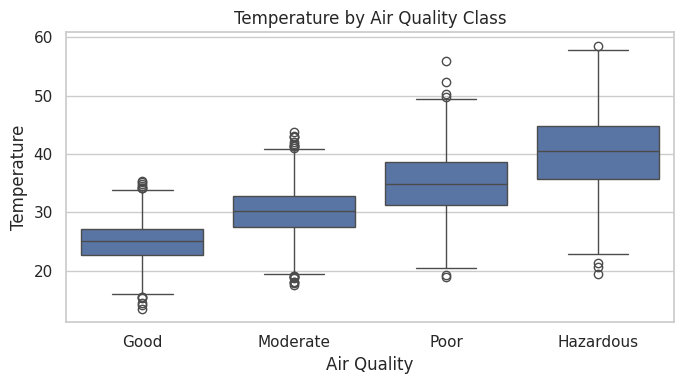

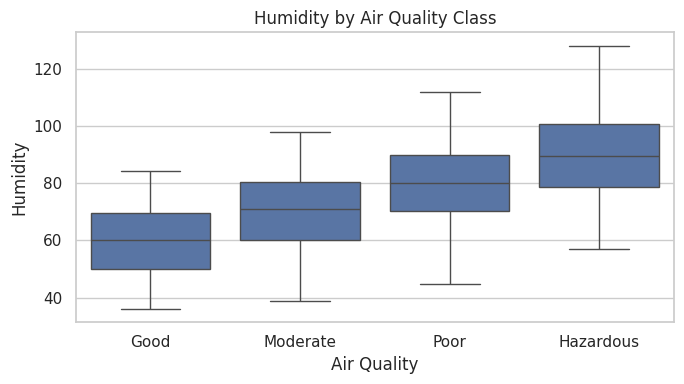

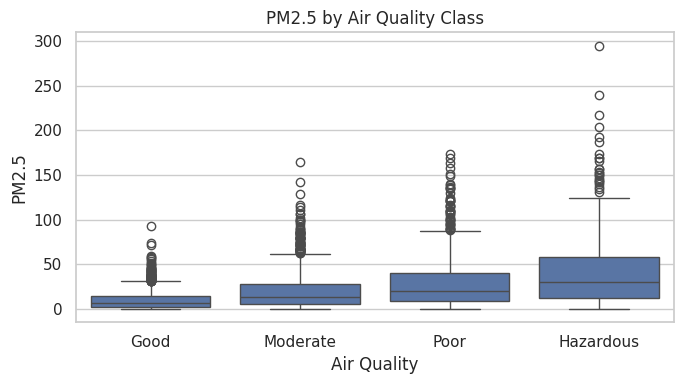

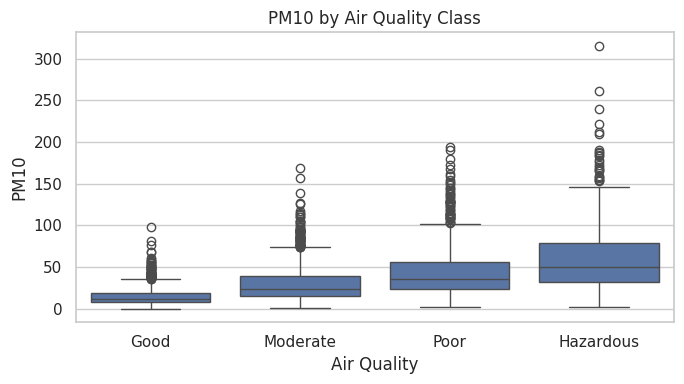

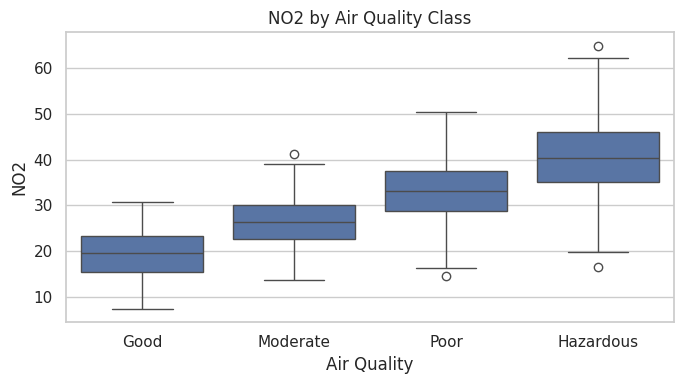

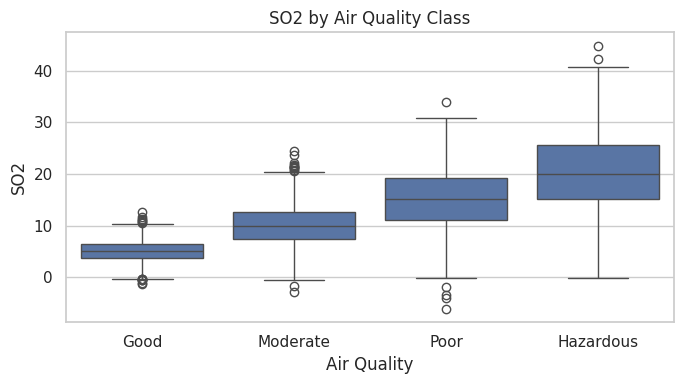

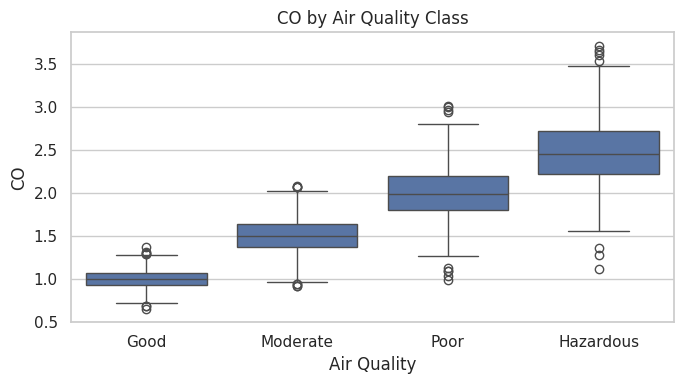

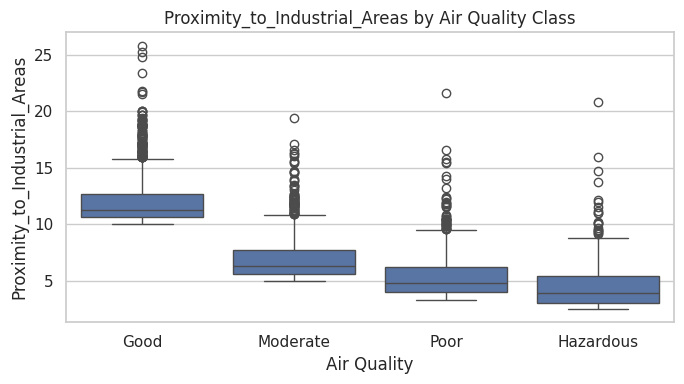

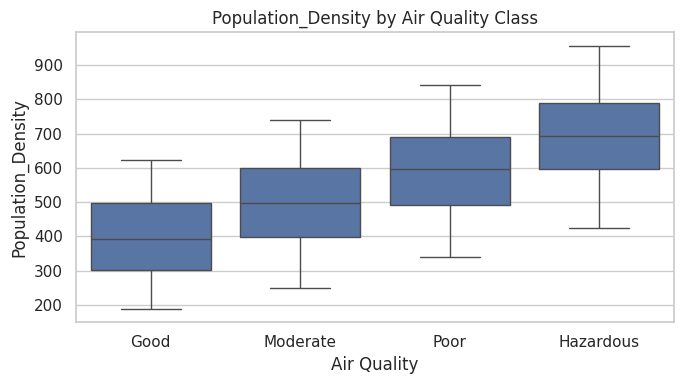

In [6]:
for col in features9:
    plt.figure(figsize=(7,4))
    sns.boxplot(data=data, x=target, y=col, order=class_order)
    plt.title(f"{col} by Air Quality Class")
    plt.tight_layout(); plt.show()


## 7. Correlation analysis

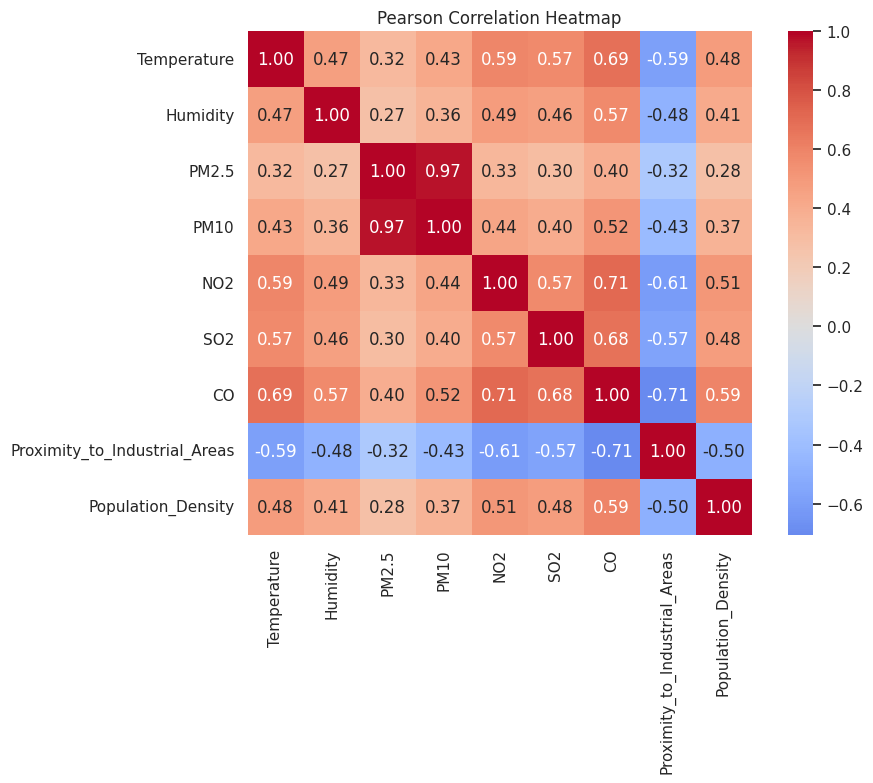

Strong feature correlations (absolute r >= 0.70):


,,Pearson r
PM2.5,PM10,0.973005
NO2,CO,0.710792
CO,Proximity_to_Industrial_Areas,-0.707581


In [7]:
corr = data[features9].corr(numeric_only=True)
plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Pearson Correlation Heatmap")
plt.tight_layout(); plt.show()

print("Strong feature correlations (absolute r >= 0.70):")
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
display(pairs[pairs.abs() >= 0.70].sort_values(key=np.abs, ascending=False).to_frame("Pearson r"))


## 8. Class-wise feature summary

In [8]:
display(data.groupby(target)[features9].agg(["mean","median","std"]).reindex(class_order).round(2))


Temperature              Humidity                PM2.5         \
                   mean median   std     mean median    std   mean median   
Air Quality                                                                 
Good              24.95  25.00  3.30    60.02  60.10  11.63   9.91   7.00   
Moderate          30.14  30.20  4.18    70.21  70.90  12.32  20.46  13.90   
Poor              34.87  34.80  5.35    80.18  80.20  12.99  29.24  19.85   
Hazardous         40.35  40.55  6.48    89.47  89.65  14.10  41.92  30.15   

                     PM10  ...   SO2    CO              \
               std   mean  ...   std  mean median  std   
Air Quality                ...                           
Good          9.71  14.99  ...  2.06  1.00   1.00  0.1   
Moderate     20.42  30.60  ...  4.02  1.51   1.50  0.2   
Poor         28.59  44.45  ...  6.19  2.00   1.99  0.3   
Hazardous    41.39  61.51  ...  8.00  2.49   2.46  0.4   

            Proximity_to_Industrial_Areas              Population_Density  \
                                     mean median   std               mean   
Air Quality                                                                 
Good                                11.99  11.30  2.02             398.94   
Moderate                             6.96   6.30  1.93             497.57   
Poor                                 5.42   4.80  2.02             594.88   
Hazardous                            4.59   3.95  2.17             696.01   

                            
            median     std  
Air Quality                 
Good         391.0  115.58  
Moderate     496.5  115.83  
Poor         597.5  118.42  
Hazardous    692.0  120.21  

[4 rows x 27 columns]

## 9. Documented cleaning rules

The original data are kept unchanged. A separate cleaned copy follows the presentation:

- Humidity above 100: mark as missing.
- SO2 below 0: mark as missing.
- PM10 below 0: mark as missing.
- PM10 below PM2.5: exclude the row because the incorrect measurement cannot be identified.
- IQR outliers are retained because extreme pollution readings may be genuine observations.
- Median imputation is fitted inside each model pipeline, using training folds only.


In [9]:
original = data.copy()
cleaned = data.copy()

humidity_bad = cleaned["Humidity"] > 100
so2_bad = cleaned["SO2"] < 0
pm10_negative = cleaned["PM10"] < 0
pm_order_bad = (
    cleaned["PM10"].notna() & cleaned["PM2.5"].notna()
    & (cleaned["PM10"] < cleaned["PM2.5"])
)

print("Humidity > 100:", int(humidity_bad.sum()))
print("SO2 < 0:", int(so2_bad.sum()))
print("PM10 < 0:", int(pm10_negative.sum()))
print("PM10 < PM2.5:", int(pm_order_bad.sum()))

cleaned.loc[humidity_bad, "Humidity"] = np.nan
cleaned.loc[so2_bad, "SO2"] = np.nan
cleaned.loc[pm10_negative, "PM10"] = np.nan
cleaned = cleaned.loc[~pm_order_bad].copy()

print("Original rows:", len(original))
print("Cleaned rows:", len(cleaned))
print("Rows excluded:", len(original) - len(cleaned))
print("Missing cells in cleaned copy:", int(cleaned[features9].isna().sum().sum()))


Humidity > 100: 195
SO2 < 0: 30
PM10 < 0: 1
PM10 < PM2.5: 32
Original rows: 5000
Cleaned rows: 4968
Rows excluded: 32
Missing cells in cleaned copy: 223


## 10. Compare original and cleaned data

In [10]:
quality_summary = pd.DataFrame({
    "Original": [len(original), int(original.isna().sum().sum()), int(original.duplicated().sum())],
    "Cleaned": [len(cleaned), int(cleaned.isna().sum().sum()), int(cleaned.duplicated().sum())]
}, index=["Rows", "Missing cells", "Duplicate rows"])
display(quality_summary)


,Original,Cleaned
Rows,5000,4968
Missing cells,0,223
Duplicate rows,0,0


## 11. One shared stratified train/test split

The split is made on the original 5,000 rows (80% train, 20% test; seed 42). The same row indices are reused for the cleaned-data experiments after excluded rows are removed. Stratification is performed on the actual `Air Quality` labels.


In [11]:
all_ids = np.arange(len(original))
train_ids, test_ids = train_test_split(
    all_ids,
    test_size=0.20,
    random_state=SEED,
    stratify=original[target]
)

orig_train = original.iloc[train_ids].copy()
orig_test = original.iloc[test_ids].copy()

clean_train = cleaned.loc[cleaned.index.isin(train_ids)].copy()
clean_test = cleaned.loc[cleaned.index.isin(test_ids)].copy()

print("Original train/test:", len(orig_train), len(orig_test))
print("Cleaned train/test:", len(clean_train), len(clean_test))
print("\nOriginal train class shares:")
display((orig_train[target].value_counts(normalize=True).reindex(class_order)*100).round(1).to_frame("Train %"))
print("\nOriginal test class shares:")
display((orig_test[target].value_counts(normalize=True).reindex(class_order)*100).round(1).to_frame("Test %"))


Original train/test: 4000 1000
Cleaned train/test: 3979 989

Original train class shares:


,Train %
Air Quality,
Good,40.0
Moderate,30.0
Poor,20.0
Hazardous,10.0



Original test class shares:


,Test %
Air Quality,
Good,40.0
Moderate,30.0
Poor,20.0
Hazardous,10.0


## 12. Model pipelines and tuning grids

In [12]:
def make_adaboost():
    tree = DecisionTreeClassifier(random_state=SEED)
    # sklearn renamed base_estimator to estimator in newer versions.
    if "estimator" in inspect.signature(AdaBoostClassifier).parameters:
        return AdaBoostClassifier(estimator=tree, random_state=SEED)
    return AdaBoostClassifier(base_estimator=tree, random_state=SEED)

def build_model_specs():
    return {
        "Logistic Regression": (
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scale", StandardScaler()),
                ("model", LogisticRegression(max_iter=3000, random_state=SEED))
            ]),
            {"model__C": [0.1, 1, 10]}
        ),
        "Random Forest": (
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("model", RandomForestClassifier(random_state=SEED, n_jobs=-1))
            ]),
            {
                "model__n_estimators": [200, 300],
                "model__min_samples_leaf": [1, 2],
                "model__max_features": ["sqrt"],
                "model__max_depth": [None]
            }
        ),
        "AdaBoost": (
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("model", make_adaboost())
            ]),
            {
                "model__n_estimators": [100, 200],
                "model__learning_rate": [0.5, 1.0],
                "model__estimator__max_depth": [2, 3]
            }
        ),
        "Gradient Boosting": (
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("model", GradientBoostingClassifier(random_state=SEED))
            ]),
            {
                "model__n_estimators": [100, 150],
                "model__learning_rate": [0.05, 0.1],
                "model__max_depth": [2, 3],
                "model__subsample": [0.8, 1.0]
            }
        )
    }

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
print("Four model families ready. CV scoring: Macro-F1.")


Four model families ready. CV scoring: Macro-F1.


## 13. Run all 16 experiments (4 models × 2 feature sets × 2 data versions)

In [13]:
results = []
fitted_models = {}
data_versions = {
    "Original": (orig_train, orig_test),
    "Cleaned": (clean_train, clean_test)
}
feature_sets = {"4 features": features4, "9 features": features9}

for version, (train_frame, test_frame) in data_versions.items():
    for feature_label, feature_cols in feature_sets.items():
        X_train = train_frame[feature_cols]
        y_train = train_frame[target]
        X_test = test_frame[feature_cols]
        y_test = test_frame[target]

        for model_name, (pipeline, param_grid) in build_model_specs().items():
            search = GridSearchCV(
                estimator=clone(pipeline),
                param_grid=param_grid,
                scoring="f1_macro",
                cv=cv,
                n_jobs=-1,
                refit=True,
                error_score="raise"
            )
            search.fit(X_train, y_train)
            predictions = search.predict(X_test)
            probabilities = search.predict_proba(X_test)
            model_classes = search.best_estimator_.named_steps["model"].classes_

            row = {
                "Data": version,
                "Features": feature_label,
                "Model": model_name,
                "CV Macro-F1": search.best_score_,
                "Accuracy": accuracy_score(y_test, predictions),
                "Precision": precision_score(y_test, predictions, average="macro", zero_division=0),
                "Recall": recall_score(y_test, predictions, average="macro", zero_division=0),
                "Macro-F1": f1_score(y_test, predictions, average="macro", zero_division=0),
                "Weighted-F1": f1_score(y_test, predictions, average="weighted", zero_division=0),
                "ROC-AUC OvR": roc_auc_score(
                    y_test, probabilities, labels=model_classes,
                    multi_class="ovr", average="macro"
                ),
                "Best Params": search.best_params_
            }
            results.append(row)
            fitted_models[(version, feature_label, model_name)] = {
                "estimator": search.best_estimator_,
                "X_test": X_test,
                "y_test": y_test,
                "predictions": predictions,
                "probabilities": probabilities,
                "classes": model_classes
            }
            print(version, "|", feature_label, "|", model_name,
                  "| Macro-F1:", round(row["Macro-F1"], 4))

results_df = pd.DataFrame(results).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
display(results_df.drop(columns=["Best Params"]).round(4))


Original | 4 features | Logistic Regression | Macro-F1: 0.7437
Original | 4 features | Random Forest | Macro-F1: 0.7023
Original | 4 features | AdaBoost | Macro-F1: 0.684
Original | 4 features | Gradient Boosting | Macro-F1: 0.7307
Original | 9 features | Logistic Regression | Macro-F1: 0.8988
Original | 9 features | Random Forest | Macro-F1: 0.9223
Original | 9 features | AdaBoost | Macro-F1: 0.928
Original | 9 features | Gradient Boosting | Macro-F1: 0.9274
Cleaned | 4 features | Logistic Regression | Macro-F1: 0.7283
Cleaned | 4 features | Random Forest | Macro-F1: 0.7115
Cleaned | 4 features | AdaBoost | Macro-F1: 0.6893
Cleaned | 4 features | Gradient Boosting | Macro-F1: 0.7238
Cleaned | 9 features | Logistic Regression | Macro-F1: 0.9044
Cleaned | 9 features | Random Forest | Macro-F1: 0.9294
Cleaned | 9 features | AdaBoost | Macro-F1: 0.9214
Cleaned | 9 features | Gradient Boosting | Macro-F1: 0.9312


,Data,Features,Model,CV Macro-F1,Accuracy,Precision,Recall,Macro-F1,Weighted-F1,ROC-AUC OvR
0,Cleaned,9 features,Gradient Boosting,0.9304,0.9535,0.9346,0.9282,0.9312,0.9534,0.9936
1,Cleaned,9 features,Random Forest,0.9330,0.9535,0.9365,0.9237,0.9294,0.9532,0.9932
2,Original,9 features,AdaBoost,0.9178,0.9520,0.9330,0.9242,0.9280,0.9520,0.9896
3,Original,9 features,Gradient Boosting,0.9299,0.9510,0.9359,0.9204,0.9274,0.9506,0.9928
4,Original,9 features,Random Forest,0.9348,0.9500,0.9318,0.9150,0.9223,0.9496,0.9937
5,Cleaned,9 features,AdaBoost,0.9169,0.9464,0.9246,0.9190,0.9214,0.9466,0.9904
6,Cleaned,9 features,Logistic Regression,0.9126,0.9333,0.9132,0.8973,0.9044,0.9328,0.9909
7,Original,9 features,Logistic Regression,0.9166,0.9290,0.9096,0.8906,0.8988,0.9285,0.9912
8,Original,4 features,Logistic Regression,0.7190,0.7770,0.7593,0.7323,0.7437,0.7761,0.9329
9,Original,4 features,Gradient Boosting,0.7071,0.7710,0.7417,0.7225,0.7307,0.7692,0.9290


## 14. Compare the 16 experiments against the presentation

In [14]:
comparison = results_df.pivot_table(
    index="Model", columns=["Data", "Features"], values=["Macro-F1", "ROC-AUC OvR"]
)
display(comparison.round(3))

print("Best configuration from this fresh run:")
display(results_df.head(1).drop(columns=["Best Params"]).round(4))

print("Presentation reference (not a guaranteed rerun result):")
presentation_reference = pd.DataFrame([
    ["Logistic Regression", 0.704, 0.923, 0.693, 0.920],
    ["Random Forest",       0.677, 0.935, 0.654, 0.934],
    ["AdaBoost",             0.667, 0.925, 0.683, 0.929],
    ["Gradient Boosting",    0.695, 0.933, 0.700, 0.939],
], columns=["Model", "Original 4F", "Original 9F", "Cleaned 4F", "Cleaned 9F"])
display(presentation_reference)


Macro-F1                                  ROC-AUC OvR  \
Data                   Cleaned              Original                Cleaned   
Features            4 features 9 features 4 features 9 features  4 features   
Model                                                                         
AdaBoost                 0.689      0.921      0.684      0.928       0.875   
Gradient Boosting        0.724      0.931      0.731      0.927       0.925   
Logistic Regression      0.728      0.904      0.744      0.899       0.929   
Random Forest            0.711      0.929      0.702      0.922       0.919   

                                                      
Data                             Original             
Features            9 features 4 features 9 features  
Model                                                 
AdaBoost                 0.990      0.878      0.990  
Gradient Boosting        0.994      0.929      0.993  
Logistic Regression      0.991      0.933      0.991  
Random Forest            0.993      0.922      0.994

Best configuration from this fresh run:


,Data,Features,Model,CV Macro-F1,Accuracy,Precision,Recall,Macro-F1,Weighted-F1,ROC-AUC OvR
0,Cleaned,9 features,Gradient Boosting,0.9304,0.9535,0.9346,0.9282,0.9312,0.9534,0.9936


Presentation reference (not a guaranteed rerun result):


,Model,Original 4F,Original 9F,Cleaned 4F,Cleaned 9F
0,Logistic Regression,0.704,0.923,0.693,0.920
1,Random Forest,0.677,0.935,0.654,0.934
2,AdaBoost,0.667,0.925,0.683,0.929
3,Gradient Boosting,0.695,0.933,0.700,0.939


## 15. Plot Macro-F1 for all 16 experiments

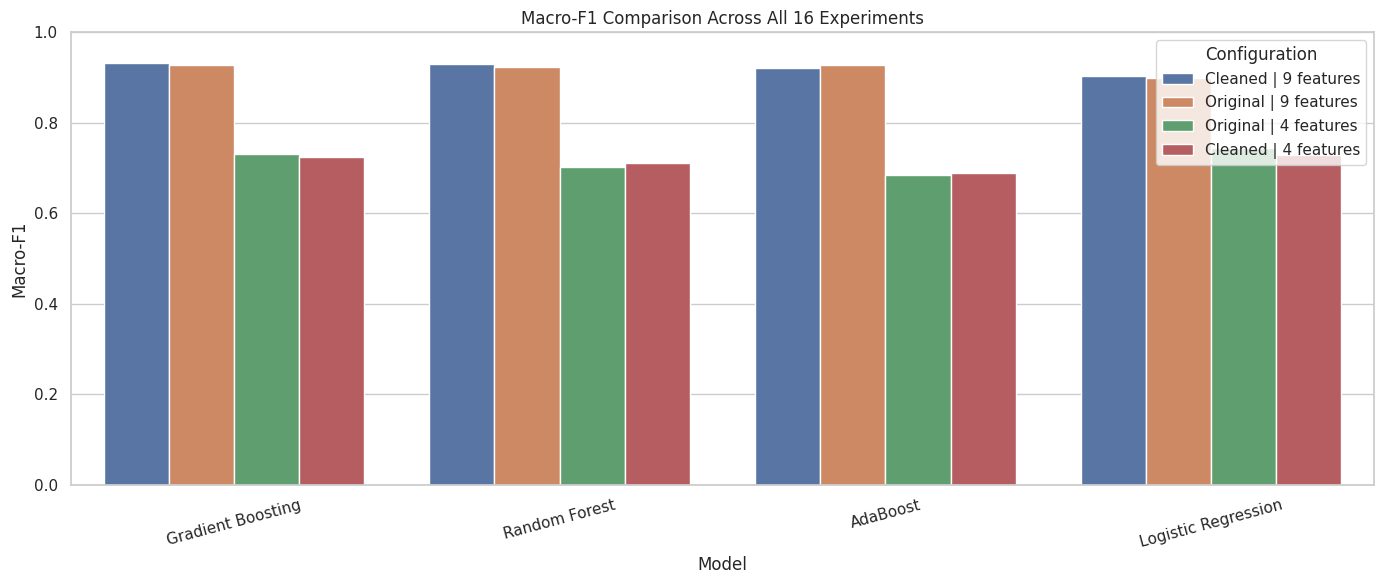

In [15]:
plot_df = results_df.copy()
plot_df["Configuration"] = plot_df["Data"] + " | " + plot_df["Features"]
plt.figure(figsize=(14,6))
sns.barplot(data=plot_df, x="Model", y="Macro-F1", hue="Configuration")
plt.ylim(0, 1)
plt.title("Macro-F1 Comparison Across All 16 Experiments")
plt.xticks(rotation=15)
plt.tight_layout(); plt.show()


## 16. Best model: classification report and confusion matrix

Best run: ('Cleaned', '9 features', 'Gradient Boosting')
              precision    recall  f1-score   support

        Good       0.99      1.00      1.00       392
    Moderate       0.97      0.96      0.96       297
        Poor       0.88      0.90      0.89       200
   Hazardous       0.89      0.85      0.87       100

    accuracy                           0.95       989
   macro avg       0.93      0.93      0.93       989
weighted avg       0.95      0.95      0.95       989



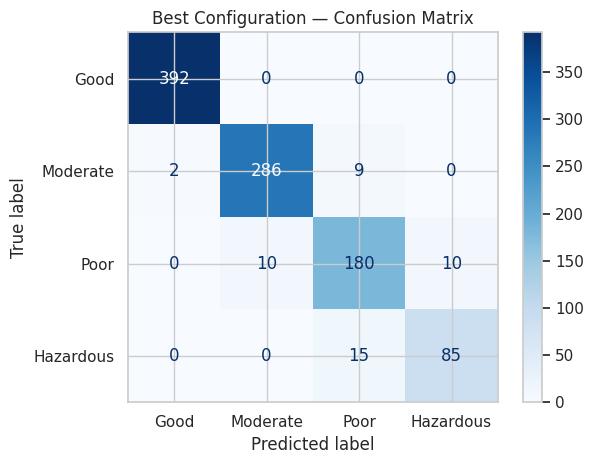

In [16]:
best_row = results_df.iloc[0]
best_key = (best_row["Data"], best_row["Features"], best_row["Model"])
best_result = fitted_models[best_key]
best_estimator = best_result["estimator"]
best_y = best_result["y_test"]
best_pred = best_result["predictions"]
best_prob = best_result["probabilities"]
best_classes = best_result["classes"]

print("Best run:", best_key)
print(classification_report(best_y, best_pred, labels=class_order, zero_division=0))
cm = confusion_matrix(best_y, best_pred, labels=class_order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_order)
disp.plot(cmap="Blues", values_format="d")
plt.title("Best Configuration — Confusion Matrix")
plt.tight_layout(); plt.show()


## 17. Confusion matrices for each model using cleaned 9-feature data

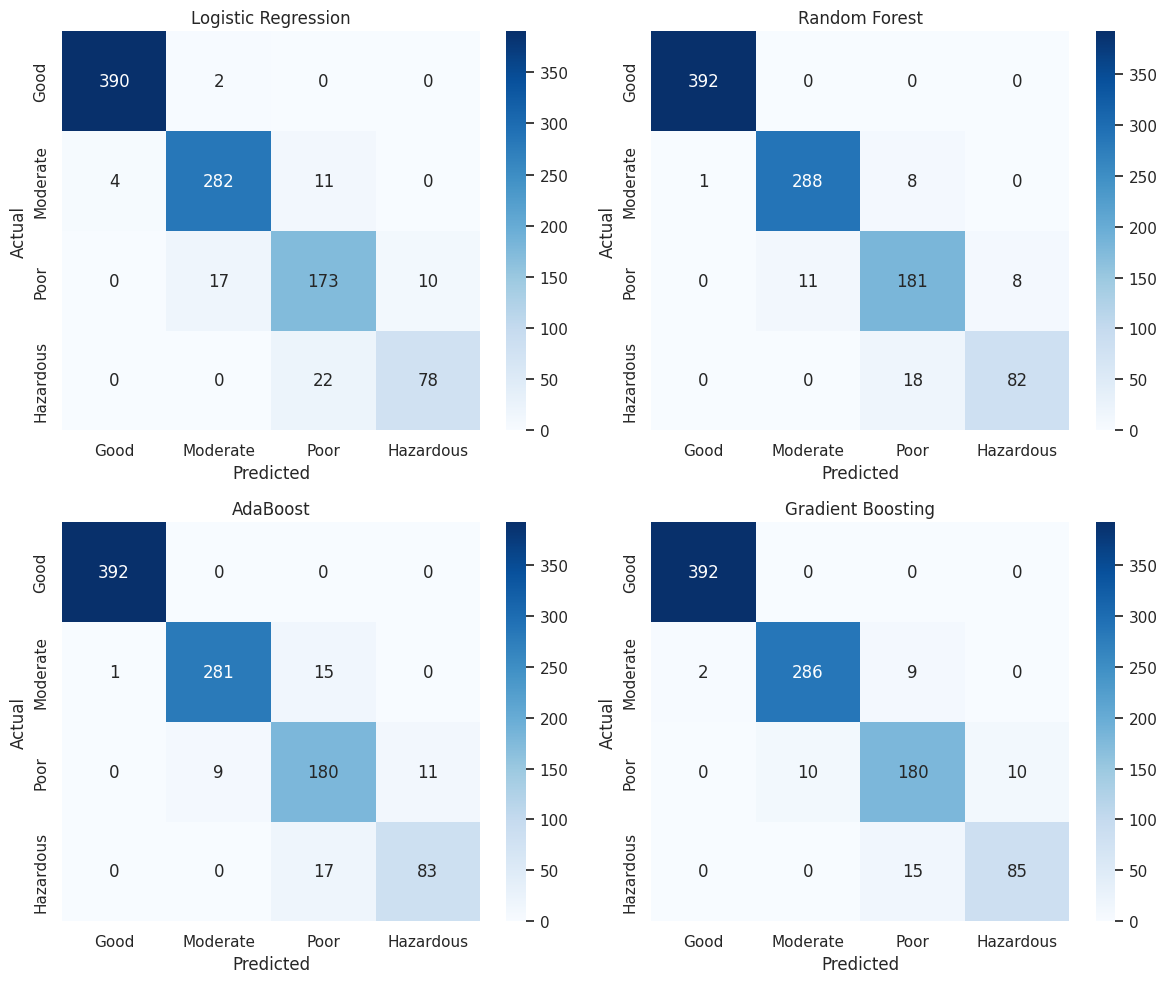

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12,10))
for ax, model_name in zip(axes.ravel(), build_model_specs().keys()):
    item = fitted_models[("Cleaned", "9 features", model_name)]
    cm = confusion_matrix(item["y_test"], item["predictions"], labels=class_order)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_order, yticklabels=class_order, ax=ax)
    ax.set_title(model_name)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()


## 18. ROC curves (One-vs-Rest) for the best configuration

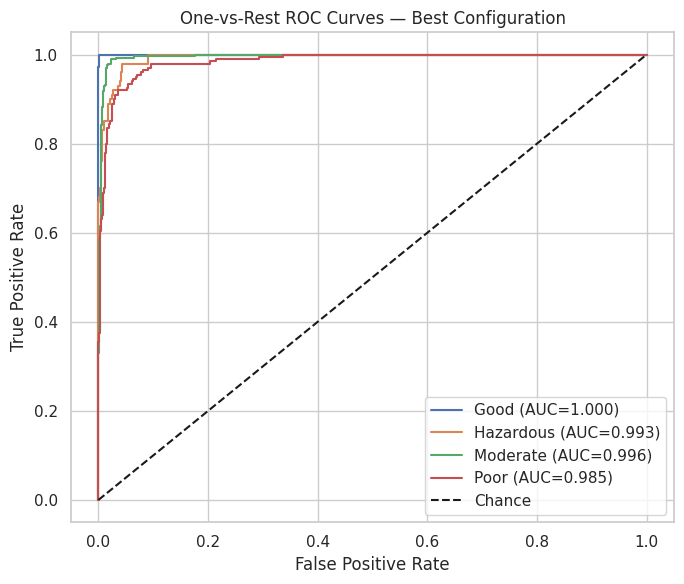

In [18]:
y_bin = label_binarize(best_y, classes=best_classes)
plt.figure(figsize=(7,6))
for i, class_name in enumerate(best_classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], best_prob[:, i])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_name} (AUC={class_auc:.3f})")
plt.plot([0,1], [0,1], "k--", label="Chance")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves — Best Configuration")
plt.legend(); plt.tight_layout(); plt.show()


## 19. Feature importance for the best tree-based model (if applicable)

,Feature,Importance
6,CO,0.613962
7,Proximity_to_Industrial_Areas,0.259718
4,NO2,0.042101
0,Temperature,0.027311
5,SO2,0.019405
8,Population_Density,0.016716
1,Humidity,0.010581
3,PM10,0.006182
2,PM2.5,0.004024


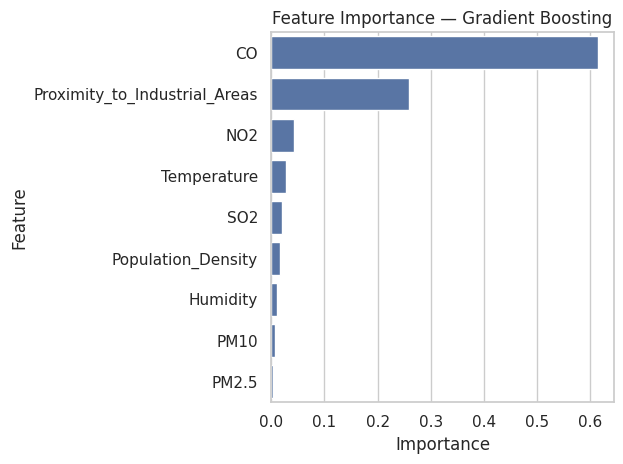

In [19]:
best_model_name = best_key[2]
if best_model_name in ["Random Forest", "AdaBoost", "Gradient Boosting"]:
    fitted_classifier = best_estimator.named_steps["model"]
    importances = getattr(fitted_classifier, "feature_importances_", None)
    if importances is not None:
        best_features = features4 if best_key[1] == "4 features" else features9
        importance_df = pd.DataFrame({"Feature": best_features, "Importance": importances})
        importance_df = importance_df.sort_values("Importance", ascending=False)
        display(importance_df)
        sns.barplot(data=importance_df, x="Importance", y="Feature")
        plt.title(f"Feature Importance — {best_model_name}")
        plt.tight_layout(); plt.show()
    else:
        print("Feature importance is not available for this estimator.")
else:
    print("Best model is Logistic Regression. Inspect coefficients separately if needed.")


## 20. Four-feature vs nine-feature and original vs cleaned comparisons

In [20]:
macro_pivot = results_df.pivot_table(
    index=["Data","Model"], columns="Features", values="Macro-F1"
)
display(macro_pivot.round(4))
print("Mean Macro-F1 gain from using nine features:")
display((macro_pivot["9 features"] - macro_pivot["4 features"])
        .groupby("Data").mean().to_frame("Mean gain").round(4))

clean_compare = results_df.pivot_table(
    index=["Features","Model"], columns="Data", values="Macro-F1"
)
print("Cleaned minus original Macro-F1:")
display((clean_compare["Cleaned"] - clean_compare["Original"])
        .to_frame("Macro-F1 difference").round(4))


Features                      4 features  9 features
Data     Model                                      
Cleaned  AdaBoost                 0.6893      0.9214
         Gradient Boosting        0.7238      0.9312
         Logistic Regression      0.7283      0.9044
         Random Forest            0.7115      0.9294
Original AdaBoost                 0.6840      0.9280
         Gradient Boosting        0.7307      0.9274
         Logistic Regression      0.7437      0.8988
         Random Forest            0.7023      0.9223

Mean Macro-F1 gain from using nine features:


,Mean gain
Data,
Cleaned,0.2084
Original,0.2039


Cleaned minus original Macro-F1:


Macro-F1 difference
Features   Model                                   
4 features AdaBoost                          0.0053
           Gradient Boosting                -0.0068
           Logistic Regression              -0.0155
           Random Forest                     0.0092
9 features AdaBoost                         -0.0066
           Gradient Boosting                 0.0039
           Logistic Regression               0.0056
           Random Forest                     0.0072

## 21. Bootstrap 95% confidence interval for the best model's Macro-F1

In [21]:
rng = np.random.default_rng(SEED)
y_true_arr = np.asarray(best_y)
pred_arr = np.asarray(best_pred)
boot_scores = []
for _ in range(1000):
    sample_idx = rng.integers(0, len(y_true_arr), len(y_true_arr))
    if len(np.unique(y_true_arr[sample_idx])) < 2:
        continue
    boot_scores.append(f1_score(
        y_true_arr[sample_idx], pred_arr[sample_idx],
        labels=class_order, average="macro", zero_division=0
    ))
ci_low, ci_high = np.percentile(boot_scores, [2.5, 97.5])
print(f"Best model Macro-F1: {f1_score(best_y, best_pred, labels=class_order, average='macro'):.3f}")
print(f"Bootstrap 95% CI: {ci_low:.3f} to {ci_high:.3f}")


Best model Macro-F1: 0.931
Bootstrap 95% CI: 0.910 to 0.950


## 22. Save experiment results and trained models

In [22]:
import joblib, json, shutil

os.makedirs("pbl3_outputs/models", exist_ok=True)
os.makedirs("pbl3_outputs/figures", exist_ok=True)

results_export = results_df.drop(columns=["Best Params"])
results_export.to_csv("pbl3_outputs/all_16_experiment_results.csv", index=False)

best_summary = {
    "data": best_key[0],
    "features": best_key[1],
    "model": best_key[2],
    "accuracy": float(best_row["Accuracy"]),
    "macro_f1": float(best_row["Macro-F1"]),
    "roc_auc_ovr": float(best_row["ROC-AUC OvR"]),
    "best_params": best_row["Best Params"]
}
with open("pbl3_outputs/best_model_summary.json", "w") as f:
    json.dump(best_summary, f, indent=2)

for key, item in fitted_models.items():
    version, feature_label, model_name = key
    safe = "_".join([version, feature_label.replace(" ", ""), model_name.replace(" ", "_")])
    joblib.dump(item["estimator"], f"pbl3_outputs/models/{safe}.joblib")

print("Saved experiment table, best-model summary and all 16 fitted estimators.")


Saved experiment table, best-model summary and all 16 fitted estimators.


## 23. Download the complete results ZIP

In [23]:
shutil.make_archive("PBL3_Air_Quality_Results", "zip", "pbl3_outputs")
files.download("PBL3_Air_Quality_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 24. Presentation reference results (for checking)

The supplied presentation reports the best configuration as **Gradient Boosting + cleaned data + nine features**:

- Accuracy: **0.958**
- Macro-F1: **0.939**
- ROC-AUC (OvR): **0.995**
- Macro-F1 95% CI: **0.919 to 0.956**
- Hazardous-class recall with nine features: **0.87**

The presentation's 16 Macro-F1 / ROC-AUC pairs are:

| Model | Original 4F | Original 9F | Cleaned 4F | Cleaned 9F |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.704 / 0.925 | 0.923 / 0.994 | 0.693 / 0.921 | 0.920 / 0.993 |
| Random Forest | 0.677 / 0.909 | 0.935 / 0.995 | 0.654 / 0.905 | 0.934 / 0.994 |
| AdaBoost | 0.667 / 0.850 | 0.925 / 0.994 | 0.683 / 0.850 | 0.929 / 0.990 |
| Gradient Boosting | 0.695 / 0.917 | 0.933 / 0.994 | 0.700 / 0.919 | 0.939 / 0.995 |

A fresh run can differ if the dataset file or exact original hyperparameter search differs. Do not claim that a rerun reproduces these values unless it actually does.
